# MINGGU 1 & 2: LEARNING PROBLEM & EXPLORATORY DATA ANALYSIS (EDA)

## 1. PROJECT OVERVIEW
**Judul Proyek:** Prediksi Resiko Titik Api Harian Untuk Peringatan Dini Karhutla Di Sumatra Dan Kalimantan
**SDG yang Dipilih:** SDG 13 – Climate Action
**Target SDG:** 13.1 Memperkuat ketahanan dan kapasitas adaptasi terhadap bahaya terkait iklim.

Kebakaran hutan dan lahan (karhutla) merupakan permasalahan lingkungan yang sering terjadi di Sumatra dan Kalimantan. Proyek ini bertujuan membangun model machine learning untuk memprediksi risiko kemunculan titik api harian menggunakan data hotspot NASA FIRMS dan suhu udara ERA5-Land.

## 2. BUSINESS UNDERSTANDING
**Problem Statements:**
1. Karhutla sering terjadi tanpa peringatan dini yang akurat.
2. Data titik api dan cuaca harian belum dimanfaatkan secara optimal untuk memprediksi potensi karhutla.

**Formulasi Learning Problem:**
- **Target:** Klasifikasi biner. Memprediksi kemunculan titik api (1 = Ya/Risiko Tinggi, 0 = Tidak/Risiko Rendah).
- **Objective:** Meminimalkan Binary Cross-Entropy Loss dan memaksimalkan metrik F1-Score & Recall.
- **Data:** Gabungan data cuaca (ERA5-Land) dan titik api (NASA FIRMS) yang bersifat spatiotemporal (2019-2026).

**Solution Approach:**
- **Baseline:** Decision Tree (Aturan keputusan yang mudah diinterpretasi).
- **Advanced:** Support Vector Machine / SVM (Menangani batas non-linear dengan kernel).
- **Deep Learning:** Multilayer Perceptron / MLP dengan 3 Hidden Layers (Untuk menangkap pola tabular yang kompleks).

## 3. DATA UNDERSTANDING
Di bawah ini kita akan memuat dataset gabungan (cuaca dan hotspot) untuk melihat informasi dasar, missing values, outliers, dan melakukan visualisasi (EDA).

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

# Atur gaya visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("=== 1. MEMBACA DATA MENTAH ===")
# a. Baca data cuaca
print("Membaca data cuaca...")
# Pastikan nama file ini sesuai dengan yang Anda download dari script API
df_weather = pd.read_csv('../data/raw/data_cuaca_gabungan.csv') 
df_weather['date'] = pd.to_datetime(df_weather['date']).dt.date
df_weather['lat_round'] = df_weather['latitude'].round(1)
df_weather['lon_round'] = df_weather['longitude'].round(1)

# b. Baca data hotspot VIIRS 
# (Asumsi Anda punya file gabungan viirs-jpss1_2018_2025_Indonesia.csv di folder data/raw)
print("Membaca data titik api VIIRS...")
df_viirs = pd.read_csv('../data/raw/viirs-jpss1_2018_2025_Indonesia.csv')
df_viirs['acq_date'] = pd.to_datetime(df_viirs['acq_date']).dt.date
df_viirs['lat_round'] = df_viirs['latitude'].round(1)
df_viirs['lon_round'] = df_viirs['longitude'].round(1)

print("\n=== 2. PROSES PENGGABUNGAN DATA (MERGING) ===")
# Hitung jumlah hotspot per grid per hari
viirs_daily_grid = df_viirs.groupby(['acq_date', 'lat_round', 'lon_round']).size().reset_index(name='hotspot_count')

# Gabungkan cuaca dan jumlah hotspot
df = pd.merge(
    df_weather, 
    viirs_daily_grid, 
    left_on=['date', 'lat_round', 'lon_round'], 
    right_on=['acq_date', 'lat_round', 'lon_round'], 
    how='left'
)

# Imputasi Missing Values: Jika tidak ada data hotspot, berarti aman (0)
df['hotspot_count'] = df['hotspot_count'].fillna(0)
# Buat label biner
df['is_hotspot'] = (df['hotspot_count'] > 0).astype(int)

# Buang kolom yang tidak perlu lagi
df = df.drop(columns=['lat_round', 'lon_round', 'acq_date', 'hotspot_count'])

print("\n=== 3. INFORMASI DATASET GABUNGAN ===")
print(df.info())
print("\n=== MISSING VALUES ===")
print(df.isnull().sum())

# Simpan data gabungan ini agar nanti bisa langsung dipakai oleh Notebook 02
import os

print("\n=== 3. INFORMASI DATASET GABUNGAN ===")
print(df.info())
print("\n=== MISSING VALUES ===")
print(df.isnull().sum())

print("\n=== 4. MENYIMPAN DATA ===")
# Deteksi lokasi folder saat ini
current_dir = os.getcwd()
print(f"Lokasi Notebook saat ini berjalan: {current_dir}")

# Menentukan letak folder data yang benar
if os.path.exists('data/raw'):
    # Jika notebook dijalankan di folder utama (Prediksi-Kobong)
    base_dir = '.' 
elif os.path.exists('../data/raw'):
    # Jika notebook dijalankan di dalam folder (notebooks)
    base_dir = '..'
else:
    print("WARNING: Folder data/raw tidak ditemukan. Pastikan Anda sudah membuat folder data/raw!")
    base_dir = None

# Membuat folder dan menyimpan file di tempat yang tepat
if base_dir is not None:
    processed_dir = os.path.join(base_dir, 'data', 'processed')
    
    # Buat folder processed jika belum ada
    if not os.path.exists(processed_dir):
        os.makedirs(processed_dir)
        
    # Simpan CSV
    output_path = os.path.join(processed_dir, 'dataset_gabungan.csv')
    df.to_csv(output_path, index=False)
    
    # Tampilkan lokasi pasti filenya agar mudah dicari
    print(f"\n[SUKSES] Data gabungan telah dibuat dan disimpan tepat di:\n{os.path.abspath(output_path)}")

=== 1. MEMBACA DATA MENTAH ===
Membaca data cuaca...
Membaca data titik api VIIRS...

=== 2. PROSES PENGGABUNGAN DATA (MERGING) ===

=== 3. INFORMASI DATASET GABUNGAN ===
<class 'pandas.DataFrame'>
RangeIndex: 261261 entries, 0 to 261260
Data columns (total 12 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   latitude                      261261 non-null  float64
 1   longitude                     261261 non-null  float64
 2   date                          261261 non-null  object 
 3   precipitation_sum             261261 non-null  float64
 4   temperature_2m_max            261261 non-null  float64
 5   et0_fao_evapotranspiration    261261 non-null  float64
 6   relative_humidity_2m_min      261261 non-null  float64
 7   wind_speed_10m_max            261261 non-null  float64
 8   vapour_pressure_deficit_max   261261 non-null  float64
 9   soil_moisture_0_to_7cm_mean   261261 non-null  float64
 10  soil

### 4.4 Exploratory Data Analysis (EDA)

#### Visualisasi 1: Distribusi Kelas Target (is_hotspot)
Tujuan: Melihat apakah dataset kita seimbang antara hari yang memiliki titik api (1) dan yang aman (0).

C:\Users\ASUS\AppData\Local\Temp\ipykernel_19240\23587447.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='is_hotspot', data=df, ax=ax, palette=['#1f77b4', '#ff7f0e'])


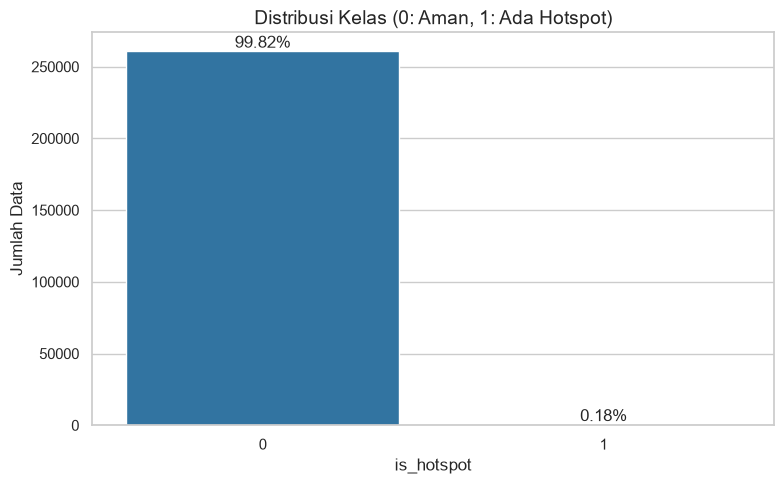

In [9]:
# EDA 1: Distribusi Kelas Target
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(x='is_hotspot', data=df, ax=ax, palette=['#1f77b4', '#ff7f0e'])
ax.set_title('Distribusi Kelas (0: Aman, 1: Ada Hotspot)', fontsize=14)
ax.set_xlabel('is_hotspot', fontsize=12)
ax.set_ylabel('Jumlah Data', fontsize=12)

# Menambahkan anotasi persentase
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.2f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom', fontsize=12)

plt.tight_layout()
plt.show()

# Insight: Dataset sangat tidak seimbang (highly imbalanced).

#### Visualisasi 2: Hubungan Suhu Maksimum dengan Kemunculan Hotspot
Tujuan: Melihat bagaimana distribusi suhu udara pada hari-hari biasa dibandingkan dengan hari terjadinya karhutla.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_19240\3428819047.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='is_hotspot', y='temperature_2m_max', data=df, ax=ax, palette=['#1f77b4', '#ff7f0e'])


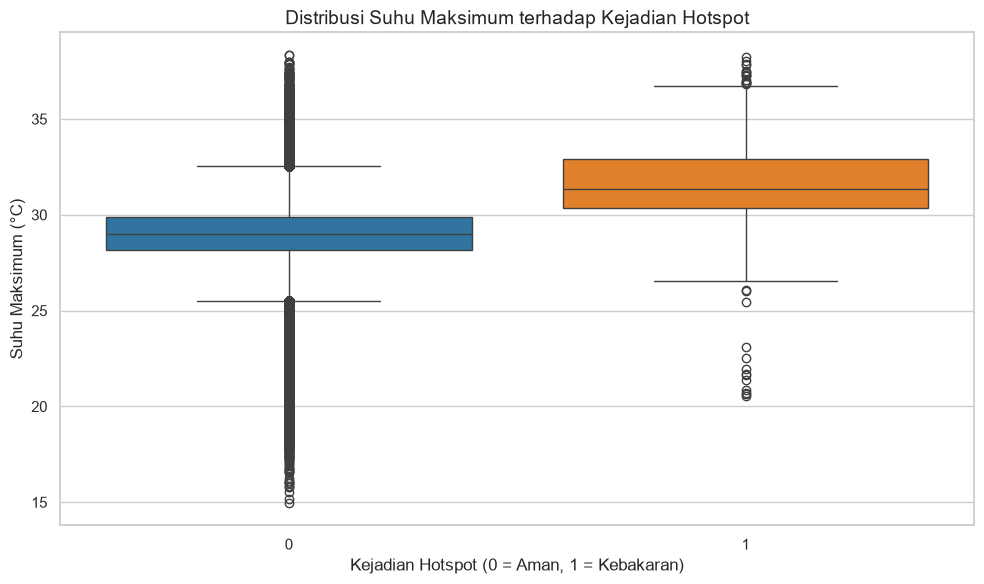

In [10]:
# EDA 2: Boxplot Suhu Maksimum
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(x='is_hotspot', y='temperature_2m_max', data=df, ax=ax, palette=['#1f77b4', '#ff7f0e'])
ax.set_title('Distribusi Suhu Maksimum terhadap Kejadian Hotspot', fontsize=14)
ax.set_xlabel('Kejadian Hotspot (0 = Aman, 1 = Kebakaran)', fontsize=12)
ax.set_ylabel('Suhu Maksimum (°C)', fontsize=12)

plt.tight_layout()
plt.show()

# Insight: Median suhu pada hari ber-hotspot jelas lebih tinggi (>30°C) dibandingkan hari biasa.

#### Visualisasi 3: Heatmap Korelasi Antar Fitur Cuaca
Tujuan: Mengidentifikasi fitur cuaca apa saja yang memiliki hubungan kuat satu sama lain, serta fitur mana yang paling berkorelasi dengan target `is_hotspot`.

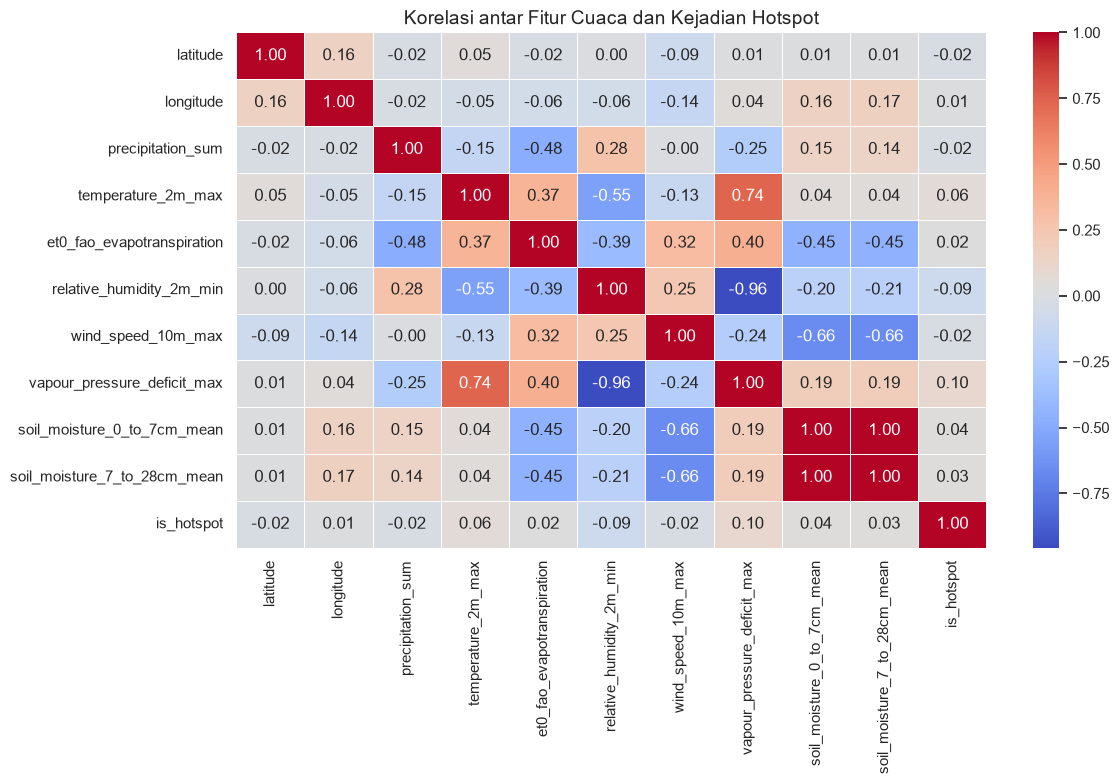

In [11]:
# EDA 3: Heatmap Korelasi
# Pilih hanya kolom numerik
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

fig, ax = plt.subplots(figsize=(12, 8))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, ax=ax)
ax.set_title('Korelasi antar Fitur Cuaca dan Kejadian Hotspot', fontsize=14)

plt.tight_layout()
plt.show()

# Insight: Defisit tekanan uap (vapour_pressure_deficit_max) berkorelasi positif paling kuat dengan target (0.10).